In [54]:
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

In [55]:
df=pd.read_csv('smartcart_customers.csv')

In [56]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0


In [57]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 22 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [58]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
Complain                0
Response                0
dtype: int64

#Data preprocessing
#Handle missing values

In [59]:
df['Income']=df['Income'].fillna(df['Income'].median())

##featuring engineering

In [60]:
#AGE
df['Age']=2026-df['Year_Birth']

In [61]:
#customer joining date
df['Dt_Customer']=pd.to_datetime(df['Dt_Customer'],dayfirst=True)
reference_date=df['Dt_Customer'].max()
df['Customer_Tenure_Days']=(reference_date-df['Dt_Customer']).dt.days

In [62]:
#spending 
df['Total_Spending']=df['MntWines']+df['MntFruits']+df['MntMeatProducts']+df['MntFishProducts']+df['MntGoldProds']

In [63]:
#Childrens
df['Total_Children']=df['Kidhome']+df['Teenhome']

In [64]:
#Education
df['Education'].value_counts()
df['Education']=df['Education'].replace({
    'Basic':'Undergraduate', '2n Cycle':'Undergraduate',
    'Graduation':'Graduate',
    'Master':'Postgraduate','PhD':'Postgraduate'  
})

In [65]:
df['Education'].value_counts()

Education
Graduate         1127
Postgraduate      856
Undergraduate     257
Name: count, dtype: int64

In [66]:
#Marital Status
df['Marital_Status'].value_counts()
df['Living_with']=df['Marital_Status'].replace({
    'Married':'Partner', 'Together':'Partner',
    'Single':'Alone','Divorced':'Alone',
    'Widow':'Alone','Absurd':'Alone','YOLO':'Alone'
})

In [67]:
df['Living_with'].value_counts()
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response', 'Age', 'Customer_Tenure_Days', 'Total_Spending',
       'Total_Children', 'Living_with'],
      dtype='object')

In [68]:
cols=['ID','Year_Birth','Marital_Status','Kidhome',
       'Teenhome','Dt_Customer']
spending_cols=['MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds']

cols_to_drop=cols + spending_cols
df_cleaned=df.drop(columns=cols_to_drop)

In [69]:
df_cleaned.shape

(2240, 15)

In [70]:
df_cleaned.head()

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Living_with
0,Graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1529,0,Alone
1,Graduate,46344.0,38,2,1,1,2,5,0,0,72,113,26,2,Alone
2,Graduate,71613.0,26,1,8,2,10,4,0,0,61,312,755,0,Partner
3,Graduate,26646.0,26,2,2,0,4,6,0,0,42,139,50,1,Partner
4,Postgraduate,58293.0,94,5,5,3,6,5,0,0,45,161,395,1,Partner


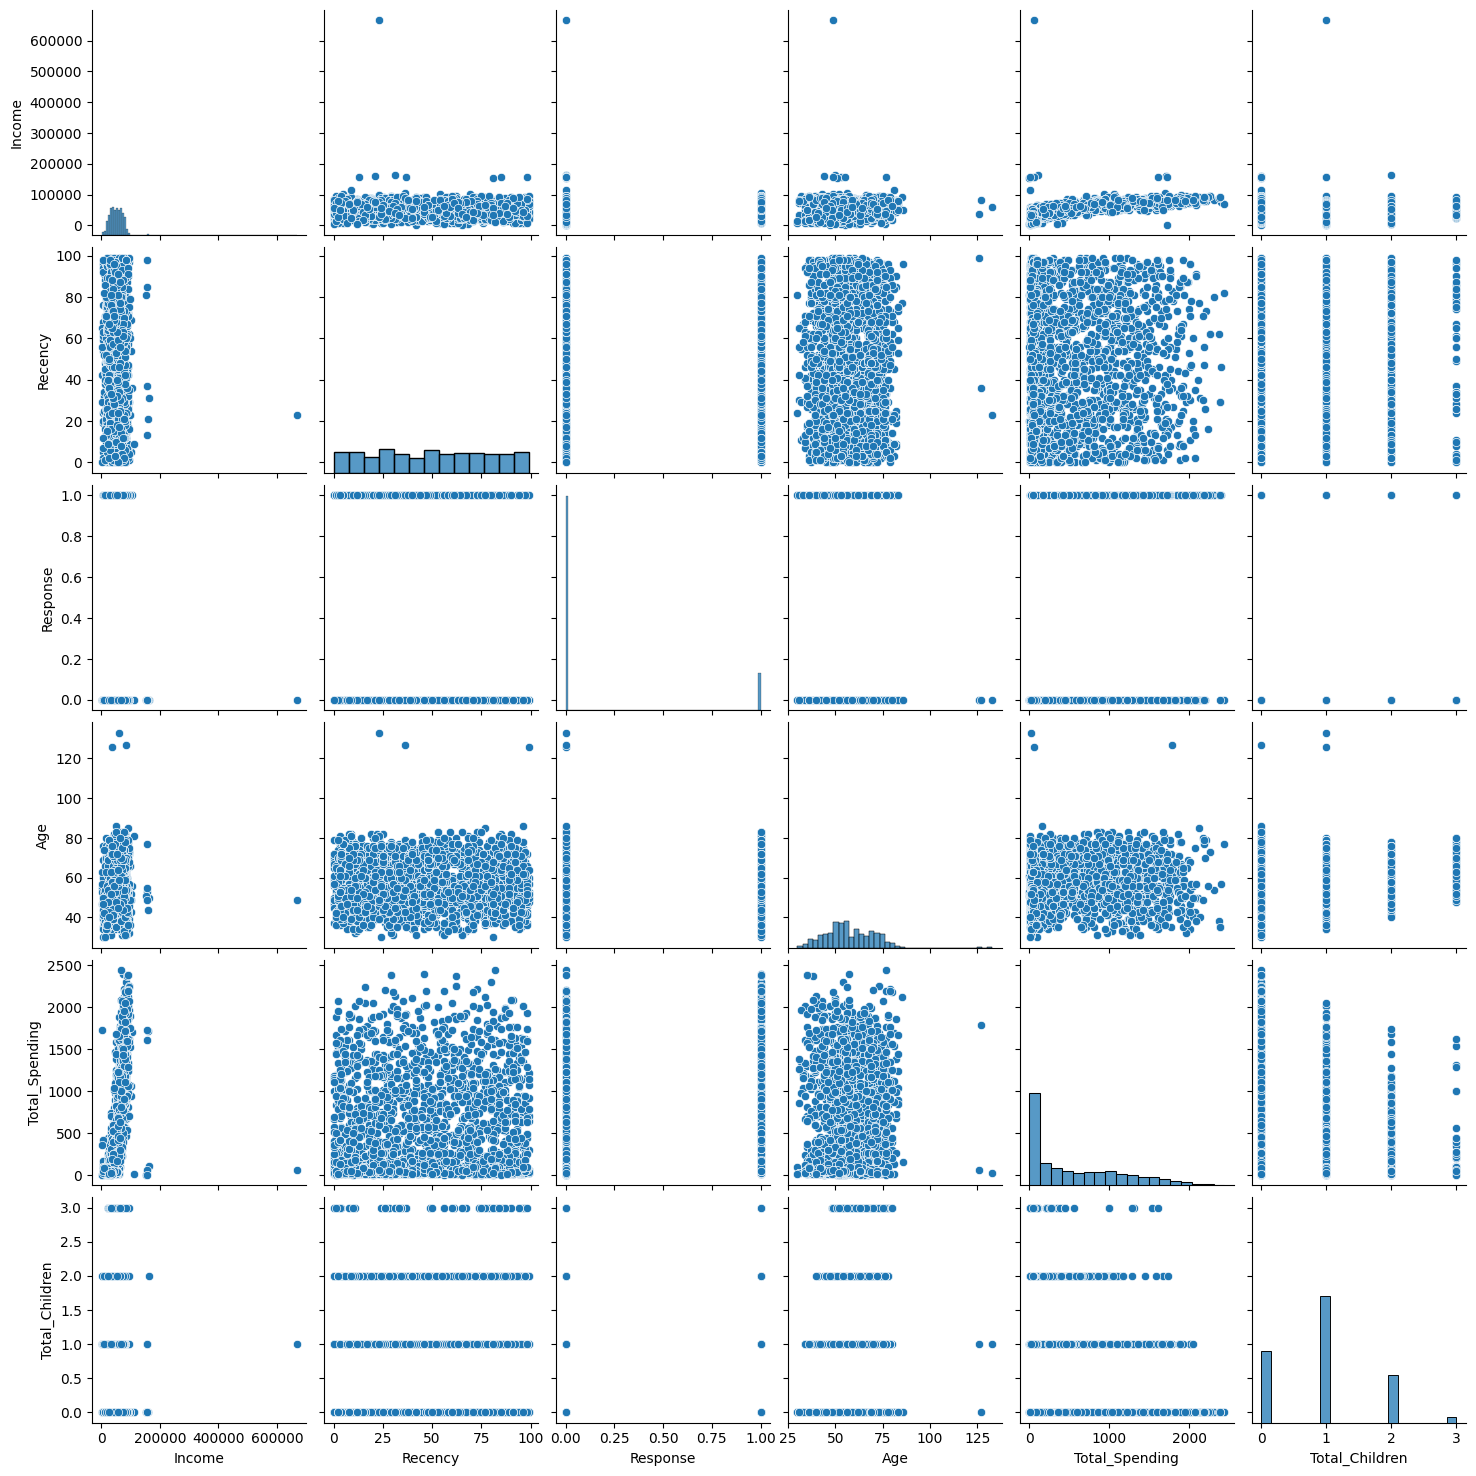

In [71]:
#outliers
cols=['Income','Recency','Response','Age','Total_Spending','Total_Children']
sns.pairplot(df_cleaned[cols])

In [72]:
#Remove outliers 
print('data size with outliers',len(df_cleaned))
df_cleaned=df_cleaned[(df_cleaned['Age']<90)]
df_cleaned=df_cleaned[(df_cleaned['Income']<600_000)]
print('data size without outliers',len(df_cleaned))

data size with outliers 2240
data size without outliers 2236


In [73]:
#heatmap
corr=df_cleaned.corr(numeric_only=True)

In [74]:
corr

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children
Income,1.000000,0.007829,-0.107169,0.450584,0.693781,0.628075,-0.646382,-0.027871,0.161121,0.198835,-0.023677,0.785057,-0.340550
Recency,0.007829,1.000000,-0.000638,-0.010776,0.025226,0.000771,-0.021850,0.005361,-0.198781,0.019396,0.024238,0.020077,0.017826
NumDealsPurchases,-0.107169,-0.000638,1.000000,0.233971,-0.008510,0.068418,0.347216,0.003636,0.002017,0.068286,0.218009,-0.058937,0.439682
NumWebPurchases,0.450584,-0.010776,0.233971,1.000000,0.378049,0.502227,-0.056204,-0.013250,0.148390,0.153873,0.191211,0.516607,-0.146429
NumCatalogPurchases,0.693781,0.025226,-0.008510,0.378049,1.000000,0.518788,-0.520376,-0.018304,0.220813,0.125285,0.095836,0.775549,-0.439631
NumStorePurchases,0.628075,0.000771,0.068418,0.502227,0.518788,1.000000,-0.429857,-0.011563,0.038702,0.139237,0.109727,0.671386,-0.321729
NumWebVisitsMonth,-0.646382,-0.021850,0.347216,-0.056204,-0.520376,-0.429857,1.000000,0.020796,-0.004397,-0.117498,0.272105,-0.490379,0.417908
Complain,-0.027871,0.005361,0.003636,-0.013250,-0.018304,-0.011563,0.020796,1.000000,0.000167,0.004450,0.035685,-0.033724,0.031480
Response,0.161121,-0.198781,0.002017,0.148390,0.220813,0.038702,-0.004397,0.000167,1.000000,-0.018557,0.194232,0.268242,-0.169451
Age,0.198835,0.019396,0.068286,0.153873,0.125285,0.139237,-0.117498,0.004450,-0.018557,1.000000,-0.016451,0.116941,0.095512


<Axes: >

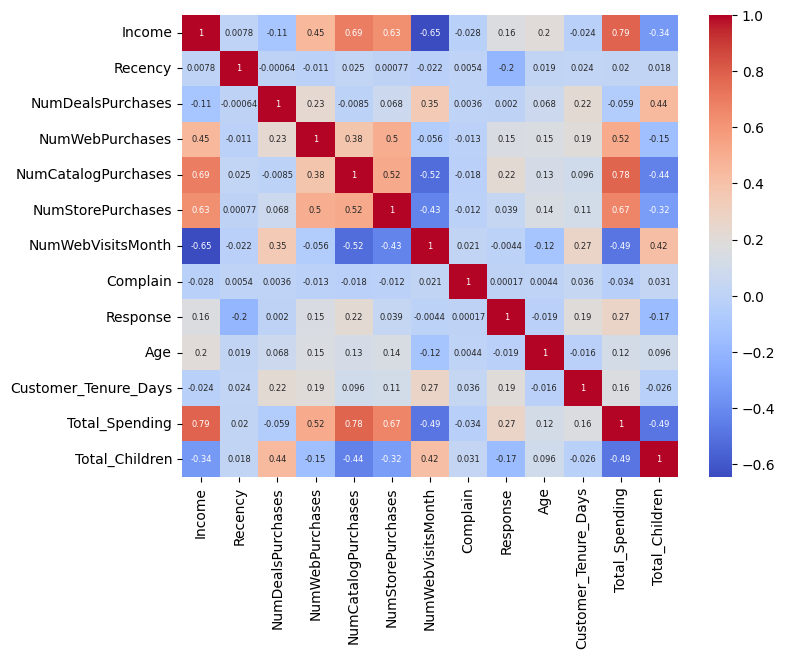

In [75]:
plt.figure(figsize=(8,6))
sns.heatmap(
    corr,
    annot=True,
    annot_kws={'size':6},
    cmap='coolwarm'
)

In [76]:
#Encoding
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder

In [77]:
transformer=ColumnTransformer(transformers=[
        ('ohe',OneHotEncoder(),['Living_with']),
        ('ordinal',OrdinalEncoder(categories=[['Undergraduate','Graduate','Postgraduate']]),['Education'])
    ]
    ,remainder='passthrough'
)

In [78]:
df_encoded=transformer.fit_transform(df_cleaned)

In [79]:
X=df_encoded

In [80]:
#scaling 
from sklearn.preprocessing import StandardScaler

In [81]:
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)

In [82]:
#visualize
X_scaled.shape

(2236, 16)

In [83]:
#2D
from sklearn.decomposition import PCA
pca=PCA(n_components=3)

In [84]:
X_pca=pca.fit_transform(X_scaled)
pca.explained_variance_ratio_

array([0.25930448, 0.12800856, 0.11328977])

Text(0.5, 0.92, '3d projection')

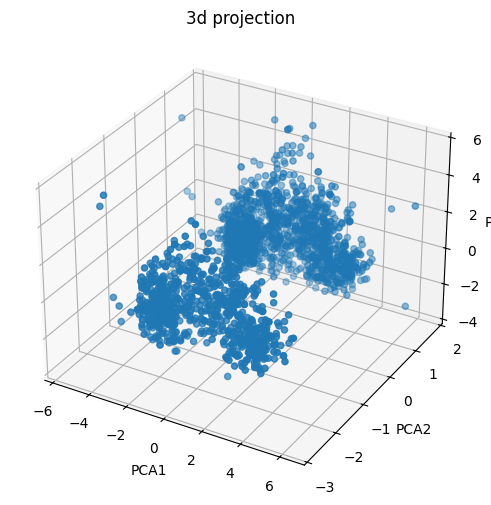

In [85]:
#plot 
fig=plt.figure(figsize=(8,6))
ax=fig.add_subplot(111,projection='3d')
ax.scatter(X_pca[:,0],X_pca[:,1],X_pca[:,2])
ax.set_xlabel('PCA1')
ax.set_ylabel('PCA2')
ax.set_zlabel('PCA3')
ax.set_title('3d projection')

#Analyze k value
1.Elbow Method

In [86]:
from sklearn.cluster import KMeans
from kneed import KneeLocator
wcss=[]
for k in range(1,11):
    kmeans=KMeans(n_clusters=k,random_state=42)
    kmeans.fit_predict(X_pca)
    wcss.append(kmeans.inertia_)

In [87]:
knee=KneeLocator(range(1,11), wcss, curve='convex', direction='decreasing')
optimal_k=knee.elbow

In [88]:
print('best k',optimal_k)

best k 4


Text(0, 0.5, 'WCSS')

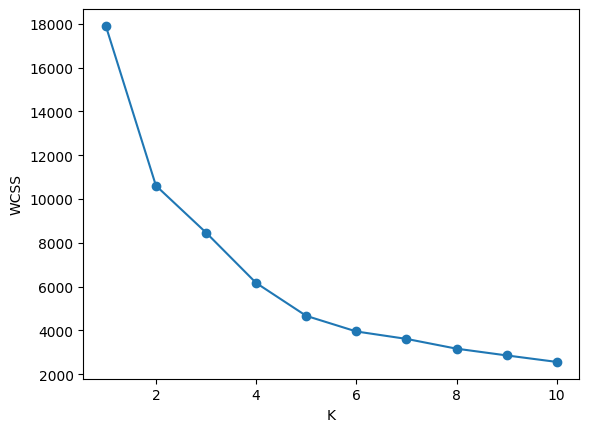

In [89]:
plt.plot(range(1,11),wcss,marker='o')
plt.xlabel('K')
plt.ylabel('WCSS')

In [90]:
##silhoutte score
from sklearn.metrics import silhouette_score
scores=[]
for k in range(2,11):
    kmeans=KMeans(n_clusters=k,random_state=42)
    labels=kmeans.fit_predict(X_pca)
    score=silhouette_score(X_pca,labels)
    scores.append(score)
    

Text(0, 0.5, 'scores')

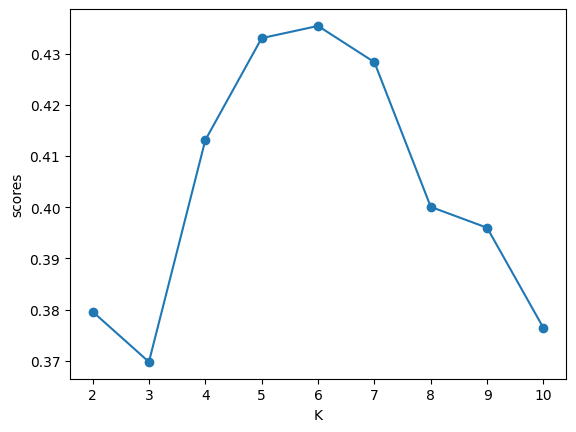

In [91]:
plt.plot(range(2,11),scores,marker='o')
plt.xlabel('K')
plt.ylabel('scores')

Text(0, 0.5, 'SS')

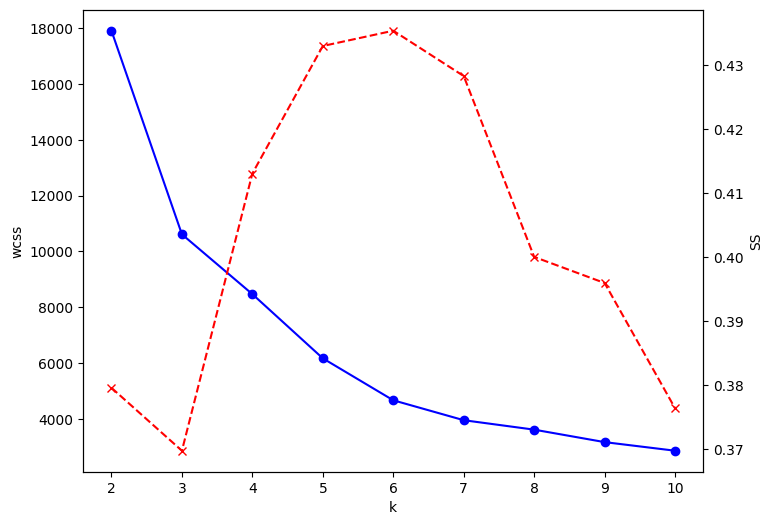

In [92]:
#combined plot
k_range=range(2,11)
fig,ax1=plt.subplots(figsize=(8,6))
ax1.plot(k_range,wcss[:len(k_range)],marker='o',color='blue')
ax1.set_xlabel('k')
ax1.set_ylabel('wcss')
ax2=ax1.twinx()
ax2.plot(k_range,scores[:len(k_range)],marker='x',color='red',linestyle='--')
ax2.set_ylabel('SS')

In [93]:
#k_means
kmeans=KMeans(n_clusters=4,random_state=42)
labels_kmeans=kmeans.fit_predict(X_pca)

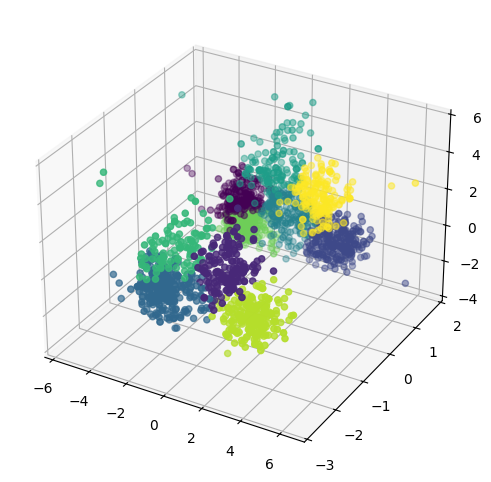

In [94]:
fig=plt.figure(figsize=(8,6))
ax=fig.add_subplot(111,projection='3d')
ax.scatter(X_pca[:,0],X_pca[:,1],X_pca[:,2],c=labels)

In [95]:
#Agglomerative Clustering
from sklearn.cluster import AgglomerativeClustering

In [96]:
agg_clf=AgglomerativeClustering(n_clusters=4,linkage='ward')
labels_agg=agg_clf.fit_predict(X_pca)

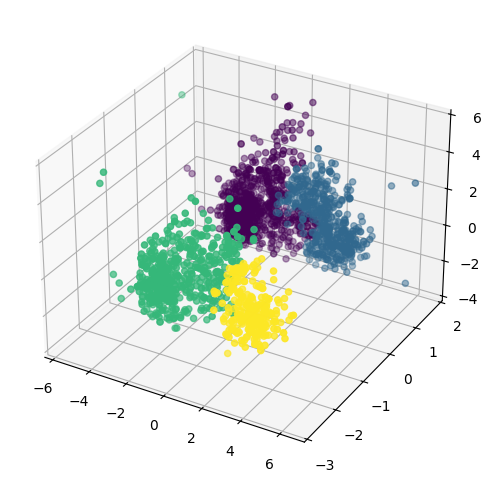

In [97]:
fig=plt.figure(figsize=(8,6))
ax=fig.add_subplot(111,projection='3d')
ax.scatter(X_pca[:,0],X_pca[:,1],X_pca[:,2],c=labels_agg)

In [110]:
X = pd.DataFrame(X, columns=df_cleaned.columns)
X['cluster'] = labels_agg

<Axes: xlabel='cluster', ylabel='count'>

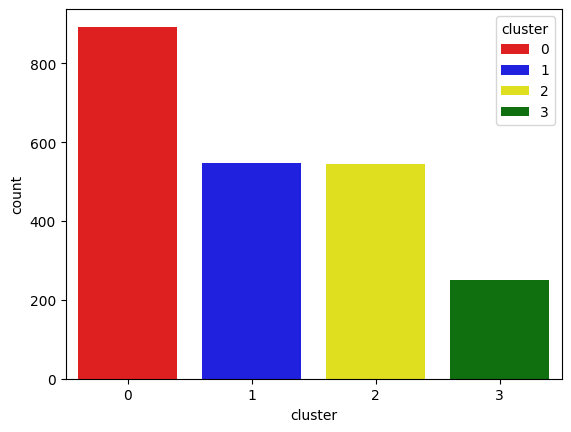

In [111]:
pal=['red','blue','yellow','green']
sns.countplot(x=X['cluster'],palette=pal,hue=X['cluster'])

In [118]:
X['Total_Spending'] = df_cleaned['Total_Spending'].values
X['Income'] = df_cleaned['Income'].values

<Axes: xlabel='Total_Spending', ylabel='Income'>

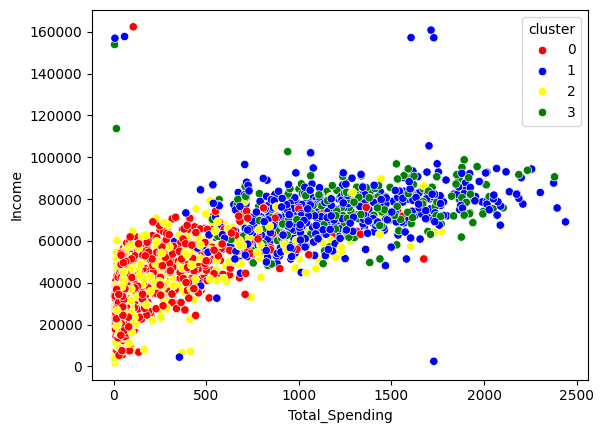

In [119]:
#Income and spending to analysize they have high relationship
sns.scatterplot(x=X['Total_Spending'],y=X['Income'],hue=X['cluster'],palette=pal)

In [123]:
#cluster summary
cluster_summary=X.groupby('cluster').mean()
print(cluster_summary)

         Education        Income  Recency  NumDealsPurchases  NumWebPurchases  \
cluster                                                                         
0              NaN  39786.833707      NaN                NaN              NaN   
1              NaN  71666.926095      NaN                NaN              NaN   
2              NaN  41475.171560      NaN                NaN              NaN   
3              NaN  75035.834000      NaN                NaN              NaN   

         NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth  Complain  \
cluster                                                                        
0                        NaN                NaN                NaN       NaN   
1                        NaN                NaN                NaN       NaN   
2                        NaN                NaN                NaN       NaN   
3                        NaN                NaN                NaN       NaN   

         Response  Age  Customer